In [4]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator
import os

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [5]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=1))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=1))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [6]:
def create_to_be_fit_array (RawData):
    return np.transpose(np.vstack((np.log10(RawData[MdotIndex]),np.log10(RawData[PIndex]),np.log10(RawData[LIndex]))))

In [7]:
M0StarData_to_be_fit = create_to_be_fit_array(M0StarData)
M1StarData_to_be_fit = create_to_be_fit_array(M1StarData)
C0StarData_to_be_fit = create_to_be_fit_array(C0StarData)
C1StarData_to_be_fit = create_to_be_fit_array(C1StarData)

In [8]:
pca_M0 = PCA()
pca_M1 = PCA()
pca_C0 = PCA()
pca_C1 = PCA()

In [9]:
def get_PCA_values (pca_set, Data_Set):
    pca_set.fit(Data_Set)
    print('n components:',pca_set.n_components_)
    print('Explained Variance Ratio:',pca_set.explained_variance_ratio_)
    print('Check - Sum of Explained Variance Ratio:', np.sum(pca_set.explained_variance_ratio_))
    #print('Explained Variance:',pca_M0.explained_variance_)
    print('Components (sorted by explained variance):\n',pca_set.components_)
    #print('Singular Values:',pca_M0.singular_values_)
    #print('Covariance:', pca_M0.get_covariance())

In [10]:
get_PCA_values (pca_M0, M0StarData_to_be_fit)

n components: 3
Explained Variance Ratio: [0.78896108 0.19111801 0.01992092]
Check - Sum of Explained Variance Ratio: 1.0
Components (sorted by explained variance):
 [[-0.98585594 -0.14759391 -0.07939834]
 [ 0.14972351 -0.56275096 -0.81295401]
 [ 0.07530557 -0.81334334  0.57688966]]


In [11]:
get_PCA_values (pca_M1, M1StarData_to_be_fit)

n components: 3
Explained Variance Ratio: [0.81720121 0.17524504 0.00755375]
Check - Sum of Explained Variance Ratio: 1.0000000000000002
Components (sorted by explained variance):
 [[ 0.92732652  0.22684097  0.29767214]
 [-0.37169303  0.46534652  0.80330374]
 [-0.0437015   0.85556752 -0.51584338]]


In [12]:
get_PCA_values (pca_C0, C0StarData_to_be_fit)

n components: 3
Explained Variance Ratio: [0.85288694 0.1337677  0.01334536]
Check - Sum of Explained Variance Ratio: 1.0
Components (sorted by explained variance):
 [[ 0.98870968  0.13828147  0.05771837]
 [ 0.10632758 -0.37603113 -0.9204863 ]
 [ 0.10558229 -0.91623077  0.38648875]]


In [13]:
get_PCA_values (pca_C1, C1StarData_to_be_fit)

n components: 3
Explained Variance Ratio: [0.80982497 0.1648434  0.02533163]
Check - Sum of Explained Variance Ratio: 1.0
Components (sorted by explained variance):
 [[ 0.94864691  0.21946281  0.22782692]
 [ 0.29382787 -0.34449301 -0.89162198]
 [-0.11719308  0.91277634 -0.39128652]]


In [14]:
# First, define function for ODR
def f110(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x[0] + B[1]*x[1] + B[2]

In [15]:
M0StarData_to_be_fit[1]

array([-6.93120769,  2.38069774,  3.74803289])

In [16]:
def do_odr_fit (data_to_fit):
    linear = Model(f110)
    transposed_data = np.transpose(data_to_fit)
    logMdotData = transposed_data[0]
    logPData = transposed_data[1]
    logLData = transposed_data[2]
    mydata = Data(np.asarray([logPData, logLData]),logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [17]:
M0_ODR_Betas = do_odr_fit(M0StarData_to_be_fit)

Beta: [10.80042178 -7.66037473 -3.45765993]
Beta Std Error: [0.52615695 0.40480572 0.46498781]
Beta Covariance: [[ 69.96626068 -51.5241314   28.19526134]
 [-51.5241314   41.4143943  -33.00797037]
 [ 28.19526134 -33.00797037  54.64383471]]
Residual Variance: 0.00395678053486869
Inverse Condition #: 0.005745925453393847
Reason(s) for Halting:
  Sum of squares convergence


In [18]:
M1_ODR_Betas = do_odr_fit(M1StarData_to_be_fit)

Beta: [ 19.57673467 -11.80318919  -2.65545863]
Beta Std Error: [1.11456547 0.73194579 0.56044723]
Beta Covariance: [[ 607.37223878 -395.17398555  235.56738591]
 [-395.17398555  261.93986855 -170.56397234]
 [ 235.56738591 -170.56397234  153.57241929]]
Residual Variance: 0.002045296278824247
Inverse Condition #: 0.0031568222553467504
Reason(s) for Halting:
  Sum of squares convergence


In [19]:
C0_ODR_Betas = do_odr_fit(C0StarData_to_be_fit)

Beta: [  8.67784364  -3.66045358 -14.44585343]
Beta Std Error: [0.23436361 0.12904191 0.32960547]
Beta Covariance: [[ 1.86459683e+01 -8.52317273e+00 -1.45871735e+01]
 [-8.52317273e+00  5.65283279e+00 -1.53012091e-02]
 [-1.45871735e+01 -1.53012091e-02  3.68802099e+01]]
Residual Variance: 0.0029457468963116633
Inverse Condition #: 0.007519688050298676
Reason(s) for Halting:
  Sum of squares convergence


In [20]:
C1_ODR_Betas = do_odr_fit(C1StarData_to_be_fit)

Beta: [  7.78840509  -3.33857983 -11.1274069 ]
Beta Std Error: [0.47304549 0.27516633 0.46210658]
Beta Covariance: [[ 76.64562359 -40.35084804 -14.82164815]
 [-40.35084804  25.93415624 -10.34167676]
 [-14.82164815 -10.34167676  73.14183729]]
Residual Variance: 0.0029195670076045633
Inverse Condition #: 0.007107679986021114
Reason(s) for Halting:
  Sum of squares convergence


In [21]:
def generate_fit_mdot (odr_betas, data):
    transposed_data = np.transpose(data)
    fit_mdot = odr_betas[0]*transposed_data[1] + odr_betas[1]*transposed_data[2] + odr_betas[2]
    return fit_mdot

In [22]:
M0_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0StarData_to_be_fit)
M1_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1StarData_to_be_fit)
C0_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas, C0StarData_to_be_fit)
C1_predicted_Mdot = generate_fit_mdot (C1_ODR_Betas, C1StarData_to_be_fit)

In [23]:
def plot_predict_vs_real (predicted_Mdot, real_Mdot, label_title=None):
    plot.scatter (real_Mdot, predicted_Mdot, s = 2)
    line_data = [-12, -9, -5, -2]
    if label_title != None:
        plot.title(label_title)
    plot.xlim([-10,-3.5])
    plot.ylim([-10,-3.5])
    plot.xlabel('Mdot Data')
    plot.ylabel('Mdot Predict')
    plot.plot(line_data, line_data, color ='k')

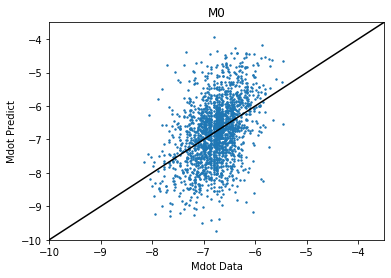

In [24]:
plot_predict_vs_real (M0_predicted_Mdot, np.transpose(M0StarData_to_be_fit)[0], label_title = 'M0')

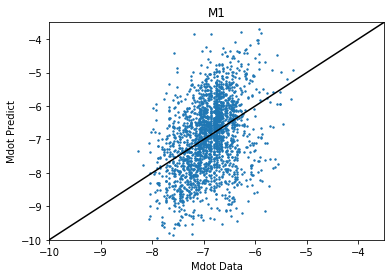

In [25]:
plot_predict_vs_real (M1_predicted_Mdot, np.transpose(M1StarData_to_be_fit)[0], label_title = 'M1')

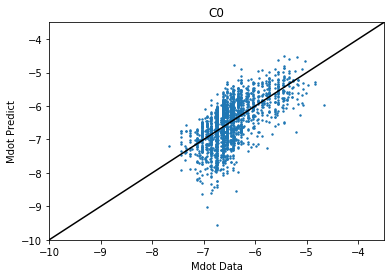

In [26]:
plot_predict_vs_real (C0_predicted_Mdot, np.transpose(C0StarData_to_be_fit)[0], label_title = 'C0')

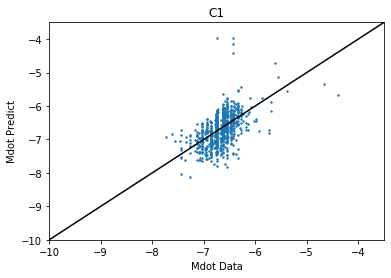

In [27]:
plot_predict_vs_real (C1_predicted_Mdot, np.transpose(C1StarData_to_be_fit)[0], label_title = 'C1')

In [28]:
def period_bin (data_to_bin):
    bin_0 = []
    bin_1 = []
    bin_2 = []
    bin_3 = []
    bin_4 = []
    bin_5 = []
    for i in range (0,len(data_to_bin)):
        working_line = data_to_bin[i]
        if working_line[1] < np.log10(100): # Period under 100 days
            bin_0.append(working_line.tolist())
        elif working_line[1] < np.log10(150): # Period between 100 and 150 days
            bin_1.append(working_line.tolist())
        elif working_line[1] < np.log10(200): # Period between 150 and 200 days
            bin_2.append(working_line.tolist())
        elif working_line[1] < np.log10(250): # Period between 200 and 250 days
            bin_3.append(working_line.tolist())
        elif working_line[1] < np.log10(300): # Period between 250 and 300 days
            bin_4.append(working_line.tolist())
        else: # Period over 300 days
            bin_5.append(working_line.tolist())
    #print(bin_0)
    return np.asarray(bin_0), np.asarray(bin_1), np.asarray(bin_2), np.asarray(bin_3), np.asarray(bin_4), np.asarray(bin_5)

In [29]:
M0_P_0_100, M0_P_100_150, M0_P_150_200, M0_P_200_250, M0_P_250_300, M0_P_300_plus = period_bin (M0StarData_to_be_fit)

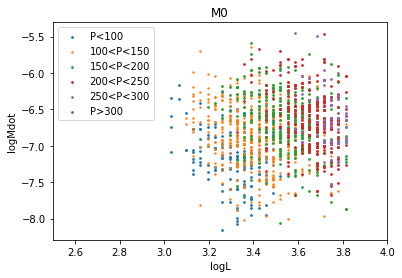

In [30]:
plot.scatter(np.transpose(M0_P_0_100)[2],np.transpose(M0_P_0_100)[0],s=3,label="P<100")
plot.scatter(np.transpose(M0_P_100_150)[2],np.transpose(M0_P_100_150)[0],s=2,label="100<P<150")
plot.scatter(np.transpose(M0_P_150_200)[2],np.transpose(M0_P_150_200)[0],s=3,label="150<P<200")
plot.scatter(np.transpose(M0_P_200_250)[2],np.transpose(M0_P_200_250)[0],s=3,label="200<P<250")
plot.scatter(np.transpose(M0_P_250_300)[2],np.transpose(M0_P_250_300)[0],s=3,label="250<P<300")
plot.scatter(np.transpose(M0_P_300_plus)[2],np.transpose(M0_P_300_plus)[0],s=3,label="P>300")
plot.xlim(2.5,4)
plot.xlabel('logL')
plot.ylabel('logMdot')
plot.title('M0')
plot.legend()

In [31]:
M1_P_0_100, M1_P_100_150, M1_P_150_200, M1_P_200_250, M1_P_250_300, M1_P_300_plus = period_bin (M1StarData_to_be_fit)

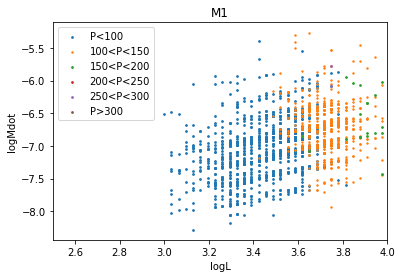

In [32]:
plot.scatter(np.transpose(M1_P_0_100)[2],np.transpose(M1_P_0_100)[0],s=3,label="P<100")
plot.scatter(np.transpose(M1_P_100_150)[2],np.transpose(M1_P_100_150)[0],s=2,label="100<P<150")
plot.scatter(np.transpose(M1_P_150_200)[2],np.transpose(M1_P_150_200)[0],s=3,label="150<P<200")
plot.scatter(np.transpose(M1_P_200_250)[2],np.transpose(M1_P_200_250)[0],s=3,label="200<P<250")
plot.scatter(np.transpose(M1_P_250_300)[2],np.transpose(M1_P_250_300)[0],s=3,label="250<P<300")
plot.scatter(np.transpose(M1_P_300_plus)[2],np.transpose(M1_P_300_plus)[0],s=3,label="P>300")
plot.xlim(2.5,4)
plot.xlabel('logL')
plot.ylabel('logMdot')
plot.title('M1')
plot.legend()

In [33]:
def period_bin_C (data_to_bin):
    bin_0 = []
    bin_1 = []
    bin_2 = []
    bin_3 = []
    bin_4 = []
    bin_5 = []
    bin_6 = []
    bin_7 = []
    for i in range (0,len(data_to_bin)):
        working_line = data_to_bin[i]
        if working_line[1] < np.log10(100): # Period under 100 days
            bin_0.append(working_line.tolist())
        elif working_line[1] < np.log10(200): # Period between 100 and 150 days
            bin_1.append(working_line.tolist())
        elif working_line[1] < np.log10(300): # Period between 150 and 200 days
            bin_2.append(working_line.tolist())
        elif working_line[1] < np.log10(400): # Period between 200 and 250 days
            bin_3.append(working_line.tolist())
        elif working_line[1] < np.log10(500): # Period between 250 and 300 days
            bin_4.append(working_line.tolist())
        elif working_line[1] < np.log10(600): # Period between 250 and 300 days
            bin_5.append(working_line.tolist())
        elif working_line[1] < np.log10(700): # Period between 250 and 300 days
            bin_6.append(working_line.tolist())
        else: # Period over 700 days
            bin_7.append(working_line.tolist())
    #print(bin_0)
    return np.asarray(bin_0), np.asarray(bin_1), np.asarray(bin_2), np.asarray(bin_3), np.asarray(bin_4), np.asarray(bin_5), np.asarray(bin_6), np.asarray(bin_7)

In [34]:
10**(np.max(np.transpose(C0StarData_to_be_fit)[1]))

817.6609999999996

In [35]:
C0_P_100, C0_P_200, C0_P_300, C0_P_400, C0_P_500, C0_P_600, C0_P_700, C0_P_800 = period_bin_C (C0StarData_to_be_fit)

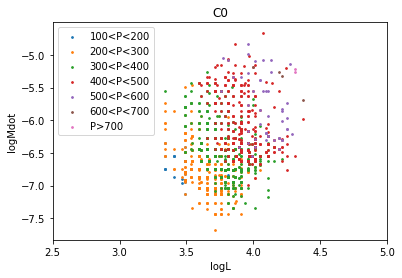

In [36]:
#plot.scatter(np.transpose(C0_P_100)[2],np.transpose(C0_P_100)[0],s=3,label="P<100")
plot.scatter(np.transpose(C0_P_200)[2],np.transpose(C0_P_200)[0],s=3,label="100<P<200")
plot.scatter(np.transpose(C0_P_300)[2],np.transpose(C0_P_300)[0],s=3,label="200<P<300")
plot.scatter(np.transpose(C0_P_400)[2],np.transpose(C0_P_400)[0],s=3,label="300<P<400")
plot.scatter(np.transpose(C0_P_500)[2],np.transpose(C0_P_500)[0],s=3,label="400<P<500")
plot.scatter(np.transpose(C0_P_600)[2],np.transpose(C0_P_600)[0],s=3,label="500<P<600")
plot.scatter(np.transpose(C0_P_700)[2],np.transpose(C0_P_700)[0],s=3,label="600<P<700")
plot.scatter(np.transpose(C0_P_800)[2],np.transpose(C0_P_800)[0],s=3,label="P>700")
plot.xlim(2.5,5)
plot.xlabel('logL')
plot.ylabel('logMdot')
plot.title('C0')
plot.legend()

In [37]:
C0_ODR_Betas_P_200 = do_odr_fit(C0_P_200)
C0_P_200_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_200, C0_P_200)
C0_ODR_Betas_P_300 = do_odr_fit(C0_P_300)
C0_P_300_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_300, C0_P_300)
C0_ODR_Betas_P_400 = do_odr_fit(C0_P_400)
C0_P_400_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_400, C0_P_400)
C0_ODR_Betas_P_500 = do_odr_fit(C0_P_500)
C0_P_500_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_500, C0_P_500)
C0_ODR_Betas_P_600 = do_odr_fit(C0_P_600)
C0_P_600_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_600, C0_P_600)
C0_ODR_Betas_P_700 = do_odr_fit(C0_P_700)
C0_P_700_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_700, C0_P_700)
C0_ODR_Betas_P_800 = do_odr_fit(C0_P_800)
C0_P_800_predicted_Mdot = generate_fit_mdot (C0_ODR_Betas_P_800, C0_P_800)

Beta: [ 24.10972366  -0.66895766 -58.85088872]
Beta Std Error: [19.98365951  0.97348813 45.01258734]
Beta Covariance: [[ 3.24355175e+05 -1.22594654e+03 -7.28486265e+05]
 [-1.22594654e+03  7.69718827e+02  5.81238736e+01]
 [-7.28486265e+05  5.81238736e+01  1.64565481e+06]]
Residual Variance: 0.001231201713191026
Inverse Condition #: 0.0005994138159506222
Reason(s) for Halting:
  Sum of squares convergence
Beta: [ 27.58306819  -3.69692177 -59.82545212]
Beta Std Error: [4.27468039 0.57637937 8.65807837]
Beta Covariance: [[ 12065.59174098  -1351.10536353 -24205.51041085]
 [ -1351.10536353    219.36037428   2458.09824944]
 [-24205.51041085   2458.09824944  49497.62416425]]
Residual Variance: 0.0015144630137729172
Inverse Condition #: 0.0009410421002315318
Reason(s) for Halting:
  Sum of squares convergence
Beta: [ 24.10669223  -3.78726433 -53.1494276 ]
Beta Std Error: [2.04817071 0.31715096 4.36957922]
Beta Covariance: [[ 4303.67452578  -493.6643494  -9021.33918963]
 [ -493.6643494    103.19

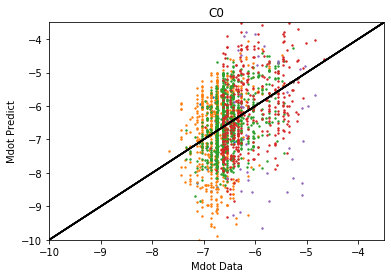

In [38]:
plot_predict_vs_real (C0_P_200_predicted_Mdot, np.transpose(C0_P_200)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_300_predicted_Mdot, np.transpose(C0_P_300)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_400_predicted_Mdot, np.transpose(C0_P_400)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_500_predicted_Mdot, np.transpose(C0_P_500)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_600_predicted_Mdot, np.transpose(C0_P_600)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_700_predicted_Mdot, np.transpose(C0_P_700)[0], label_title = 'C0')
plot_predict_vs_real (C0_P_800_predicted_Mdot, np.transpose(C0_P_800)[0], label_title = 'C0')

In [39]:
C1_P_100, C1_P_200, C1_P_300, C1_P_400, C1_P_500, C1_P_600, C1_P_700, C1_P_800 = period_bin_C (C1StarData_to_be_fit)

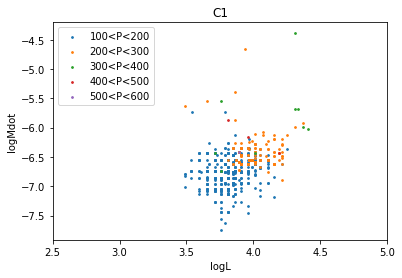

In [40]:
#plot.scatter(np.transpose(C1_P_100)[2],np.transpose(C1_P_100)[0],s=3,label="P<100")
plot.scatter(np.transpose(C1_P_200)[2],np.transpose(C1_P_200)[0],s=3,label="100<P<200")
plot.scatter(np.transpose(C1_P_300)[2],np.transpose(C1_P_300)[0],s=3,label="200<P<300")
plot.scatter(np.transpose(C1_P_400)[2],np.transpose(C1_P_400)[0],s=3,label="300<P<400")
plot.scatter(np.transpose(C1_P_500)[2],np.transpose(C1_P_500)[0],s=3,label="400<P<500")
plot.scatter(np.transpose(C1_P_600)[2],np.transpose(C1_P_600)[0],s=3,label="500<P<600")
#plot.scatter(np.transpose(C1_P_700)[2],np.transpose(C1_P_700)[0],s=3,label="600<P<700")
#plot.scatter(np.transpose(C1_P_800)[2],np.transpose(C1_P_800)[0],s=3,label="P>700")
plot.xlim(2.5,5)
plot.xlabel('logL')
plot.ylabel('logMdot')
plot.title('C1')
plot.legend()

In [41]:
M0_P_0_100_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_0_100)
M0_P_100_150_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_100_150)
M0_P_150_200_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_150_200)
M0_P_200_250_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_200_250)
M0_P_250_300_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_250_300)
M0_P_300_plus_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_P_300_plus)

In [42]:
M1_P_0_100_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_0_100)
M1_P_100_150_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_100_150)
M1_P_150_200_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_150_200)
M1_P_200_250_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_200_250)
M1_P_250_300_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_250_300)
M1_P_300_plus_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_P_300_plus)

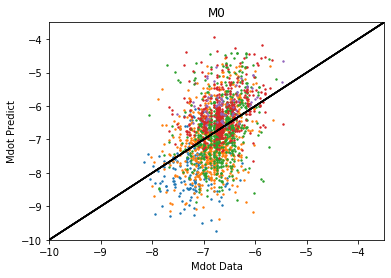

In [43]:
plot_predict_vs_real (M0_P_0_100_predicted_Mdot, np.transpose(M0_P_0_100)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_100_150_predicted_Mdot, np.transpose(M0_P_100_150)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_150_200_predicted_Mdot, np.transpose(M0_P_150_200)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_200_250_predicted_Mdot, np.transpose(M0_P_200_250)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_250_300_predicted_Mdot, np.transpose(M0_P_250_300)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_300_plus_predicted_Mdot, np.transpose(M0_P_300_plus)[0], label_title = 'M0')

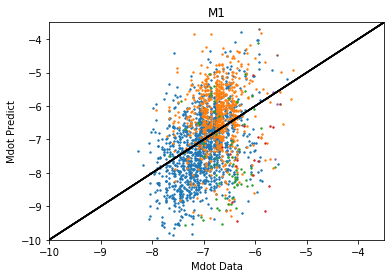

In [44]:
plot_predict_vs_real (M1_P_0_100_predicted_Mdot, np.transpose(M1_P_0_100)[0], label_title = 'M1')
plot_predict_vs_real (M1_P_100_150_predicted_Mdot, np.transpose(M1_P_100_150)[0], label_title = 'M1')
plot_predict_vs_real (M1_P_150_200_predicted_Mdot, np.transpose(M1_P_150_200)[0], label_title = 'M1')
plot_predict_vs_real (M1_P_200_250_predicted_Mdot, np.transpose(M1_P_200_250)[0], label_title = 'M1')
plot_predict_vs_real (M1_P_250_300_predicted_Mdot, np.transpose(M1_P_250_300)[0], label_title = 'M1')
plot_predict_vs_real (M1_P_300_plus_predicted_Mdot, np.transpose(M1_P_300_plus)[0], label_title = 'M1')

In [46]:
M0_ODR_Betas_P_0_100 = do_odr_fit(M0_P_0_100)
M0_P_0_100_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_0_100, M0_P_0_100)
M0_ODR_Betas_P_100_150 = do_odr_fit(M0_P_100_150)
M0_P_100_150_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_100_150, M0_P_100_150)
M0_ODR_Betas_P_150_200 = do_odr_fit(M0_P_150_200)
M0_P_150_200_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_150_200, M0_P_150_200)
M0_ODR_Betas_P_200_250 = do_odr_fit(M0_P_200_250)
M0_P_200_250_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_200_250, M0_P_200_250)
M0_ODR_Betas_P_250_300 = do_odr_fit(M0_P_250_300)
M0_P_250_300_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_250_300, M0_P_250_300)
M0_ODR_Betas_P_300 = do_odr_fit(M0_P_300_plus)
M0_P_300_plus_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_P_300, M0_P_300_plus)

Beta: [  75.88575019   -2.90417528 -145.91914153]
Beta Std Error: [31.1161965   1.60543488 58.3994858 ]
Beta Covariance: [[ 1.27427895e+06 -3.24744737e+04 -2.38408672e+06]
 [-3.24744737e+04  3.39216436e+03  5.22688023e+04]
 [-2.38408672e+06  5.22688023e+04  4.48858595e+06]]
Residual Variance: 0.000759816115521439
Inverse Condition #: 0.0005208806855904188
Reason(s) for Halting:
  Sum of squares convergence
Beta: [ 32.23086422  -6.7402804  -51.30419448]
Beta Std Error: [4.71623111 1.00349253 6.96559512]
Beta Covariance: [[ 12945.40677172  -2471.67770317 -18661.26376039]
 [ -2471.67770317    586.07585322   3172.49219469]
 [-18661.26376039   3172.49219469  28238.52440265]]
Residual Variance: 0.0017182029307696333
Inverse Condition #: 0.0014327549675918086
Reason(s) for Halting:
  Sum of squares convergence
Beta: [  57.23565397   -7.21395792 -109.15841039]
Beta Std Error: [14.26667707  1.74865722 26.34427006]
Beta Covariance: [[ 171421.67410613  -19308.62060194 -315142.07016848]
 [ -19308.

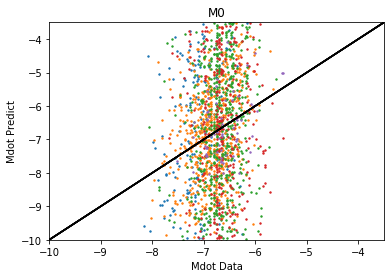

In [47]:
plot_predict_vs_real (M0_P_0_100_predicted_Mdot, np.transpose(M0_P_0_100)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_100_150_predicted_Mdot, np.transpose(M0_P_100_150)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_150_200_predicted_Mdot, np.transpose(M0_P_150_200)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_200_250_predicted_Mdot, np.transpose(M0_P_200_250)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_250_300_predicted_Mdot, np.transpose(M0_P_250_300)[0], label_title = 'M0')
plot_predict_vs_real (M0_P_300_plus_predicted_Mdot, np.transpose(M0_P_300_plus)[0], label_title = 'M0')

In [48]:
np.max(np.transpose(M0StarData_to_be_fit)[2])-np.min(np.transpose(M0StarData_to_be_fit)[2])

0.7808980507099172

In [49]:
def luminosity_bin (data_to_bin):
    bin_0 = []
    bin_1 = []
    bin_2 = []
    bin_3 = []
    bin_4 = []
    bin_5 = []
    bin_6 = []
    for i in range (0,len(data_to_bin)):
        working_line = data_to_bin[i]
        if working_line[2] < 3: 
            bin_0.append(working_line.tolist())
        elif working_line[2] < 3.2: 
            bin_1.append(working_line.tolist())
        elif working_line[2] < 3.4: 
            bin_2.append(working_line.tolist())
        elif working_line[2] < 3.6:
            bin_3.append(working_line.tolist())
        elif working_line[2] < 3.8:
            bin_4.append(working_line.tolist())
        elif working_line[2] < 4:
            bin_5.append(working_line.tolist())
        else:
            bin_6.append(working_line.tolist())
    #print(bin_0)
    return np.asarray(bin_0), np.asarray(bin_1), np.asarray(bin_2), np.asarray(bin_3), np.asarray(bin_4), np.asarray(bin_5), np.asarray(bin_6)

In [50]:
M0_L_3, M0_L_32, M0_L_34, M0_L_36, M0_L_38, M0_L_40, M0_L_plus_40 = luminosity_bin (M0StarData_to_be_fit)

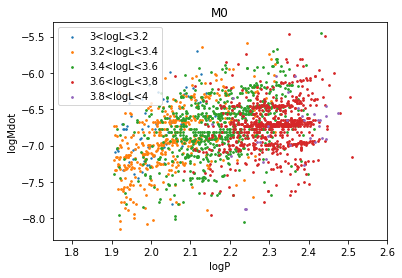

In [51]:
#plot.scatter(np.transpose(M0_L_3)[1],np.transpose(M0_L_3)[0],s=3,label="logL<3")
plot.scatter(np.transpose(M0_L_32)[1],np.transpose(M0_L_32)[0],s=2,label="3<logL<3.2")
plot.scatter(np.transpose(M0_L_34)[1],np.transpose(M0_L_34)[0],s=3,label="3.2<logL<3.4")
plot.scatter(np.transpose(M0_L_36)[1],np.transpose(M0_L_36)[0],s=3,label="3.4<logL<3.6")
plot.scatter(np.transpose(M0_L_38)[1],np.transpose(M0_L_38)[0],s=3,label="3.6<logL<3.8")
plot.scatter(np.transpose(M0_L_40)[1],np.transpose(M0_L_40)[0],s=3,label="3.8<logL<4")
#plot.scatter(np.transpose(M0_L_plus_40)[1],np.transpose(M0_L_plus_40)[0],s=3,label="logL>4")
plot.xlim(1.75,2.6)
plot.xlabel('logP')
plot.ylabel('logMdot')
plot.title('M0')
plot.legend()

In [52]:
M1_L_3, M1_L_32, M1_L_34, M1_L_36, M1_L_38, M1_L_40, M1_L_plus_40 = luminosity_bin (M1StarData_to_be_fit)

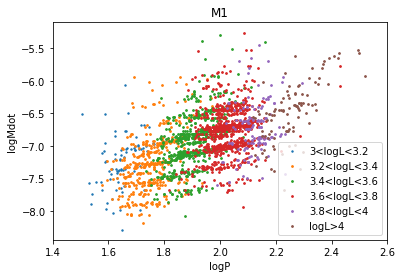

In [53]:
#plot.scatter(np.transpose(M1_L_3)[1],np.transpose(M1_L_3)[0],s=3,label="logL<3")
plot.scatter(np.transpose(M1_L_32)[1],np.transpose(M1_L_32)[0],s=2,label="3<logL<3.2")
plot.scatter(np.transpose(M1_L_34)[1],np.transpose(M1_L_34)[0],s=3,label="3.2<logL<3.4")
plot.scatter(np.transpose(M1_L_36)[1],np.transpose(M1_L_36)[0],s=3,label="3.4<logL<3.6")
plot.scatter(np.transpose(M1_L_38)[1],np.transpose(M1_L_38)[0],s=3,label="3.6<logL<3.8")
plot.scatter(np.transpose(M1_L_40)[1],np.transpose(M1_L_40)[0],s=3,label="3.8<logL<4")
plot.scatter(np.transpose(M1_L_plus_40)[1],np.transpose(M1_L_plus_40)[0],s=3,label="logL>4")
plot.xlim(1.4,2.6)
plot.xlabel('logP')
plot.ylabel('logMdot')
plot.title('M1')
plot.legend()

In [54]:
C0_L_3, C0_L_32, C0_L_34, C0_L_36, C0_L_38, C0_L_40, C0_L_plus_40 = luminosity_bin (C0StarData_to_be_fit)

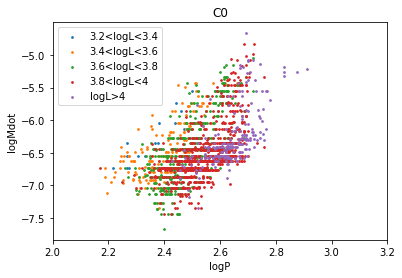

In [55]:
#plot.scatter(np.transpose(C0_L_3)[1],np.transpose(C0_L_3)[0],s=3,label="logL<3")
#plot.scatter(np.transpose(C0_L_32)[1],np.transpose(C0_L_32)[0],s=2,label="3<logL<3.2")
plot.scatter(np.transpose(C0_L_34)[1],np.transpose(C0_L_34)[0],s=3,label="3.2<logL<3.4")
plot.scatter(np.transpose(C0_L_36)[1],np.transpose(C0_L_36)[0],s=3,label="3.4<logL<3.6")
plot.scatter(np.transpose(C0_L_38)[1],np.transpose(C0_L_38)[0],s=3,label="3.6<logL<3.8")
plot.scatter(np.transpose(C0_L_40)[1],np.transpose(C0_L_40)[0],s=3,label="3.8<logL<4")
plot.scatter(np.transpose(C0_L_plus_40)[1],np.transpose(C0_L_plus_40)[0],s=3,label="logL>4")
plot.xlim(2,3.2)
plot.xlabel('logP')
plot.ylabel('logMdot')
plot.title('C0')
plot.legend()

In [56]:
C1_L_3, C1_L_32, C1_L_34, C1_L_36, C1_L_38, C1_L_40, C1_L_plus_40 = luminosity_bin (C1StarData_to_be_fit)

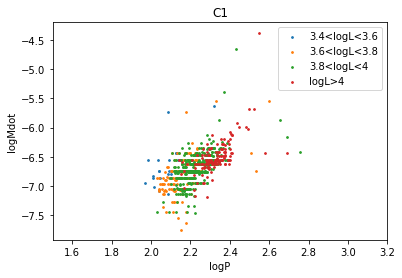

In [57]:
#plot.scatter(np.transpose(C1_L_3)[1],np.transpose(C1_L_3)[0],s=3,label="logL<3")
#plot.scatter(np.transpose(C1_L_32)[1],np.transpose(C1_L_32)[0],s=2,label="3<logL<3.2")
#plot.scatter(np.transpose(C1_L_34)[1],np.transpose(C1_L_34)[0],s=3,label="3.2<logL<3.4")
plot.scatter(np.transpose(C1_L_36)[1],np.transpose(C1_L_36)[0],s=3,label="3.4<logL<3.6")
plot.scatter(np.transpose(C1_L_38)[1],np.transpose(C1_L_38)[0],s=3,label="3.6<logL<3.8")
plot.scatter(np.transpose(C1_L_40)[1],np.transpose(C1_L_40)[0],s=3,label="3.8<logL<4")
plot.scatter(np.transpose(C1_L_plus_40)[1],np.transpose(C1_L_plus_40)[0],s=3,label="logL>4")
plot.xlim(1.5,3.2)
plot.xlabel('logP')
plot.ylabel('logMdot')
plot.title('C1')
plot.legend()

In [58]:
#M0_L_3_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_3) # Empty Array
M0_L_32_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_32)
M0_L_34_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_34)
M0_L_36_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_36)
M0_L_38_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_38)
M0_L_40_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_40)
#M0_L_plus_40_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas, M0_L_plus_40) # Empty Array

In [59]:
#M1_L_3_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_3) # Empty Array
M1_L_32_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_32)
M1_L_34_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_34)
M1_L_36_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_36)
M1_L_38_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_38)
M1_L_40_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_40)
M1_L_plus_40_predicted_Mdot = generate_fit_mdot (M1_ODR_Betas, M1_L_plus_40)

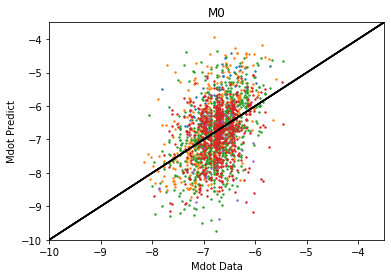

In [60]:
plot_predict_vs_real (M0_L_32_predicted_Mdot, np.transpose(M0_L_32)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_34_predicted_Mdot, np.transpose(M0_L_34)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_36_predicted_Mdot, np.transpose(M0_L_36)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_38_predicted_Mdot, np.transpose(M0_L_38)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_40_predicted_Mdot, np.transpose(M0_L_40)[0], label_title = 'M0')

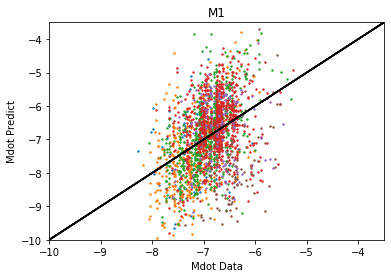

In [61]:
plot_predict_vs_real (M1_L_32_predicted_Mdot, np.transpose(M1_L_32)[0], label_title = 'M1')
plot_predict_vs_real (M1_L_34_predicted_Mdot, np.transpose(M1_L_34)[0], label_title = 'M1')
plot_predict_vs_real (M1_L_36_predicted_Mdot, np.transpose(M1_L_36)[0], label_title = 'M1')
plot_predict_vs_real (M1_L_38_predicted_Mdot, np.transpose(M1_L_38)[0], label_title = 'M1')
plot_predict_vs_real (M1_L_40_predicted_Mdot, np.transpose(M1_L_40)[0], label_title = 'M1')
plot_predict_vs_real (M1_L_plus_40_predicted_Mdot, np.transpose(M1_L_plus_40)[0], label_title = 'M1')

In [62]:
M0_ODR_Betas_L_32 = do_odr_fit(M0_L_32)
M0_L_32_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_L_32, M0_L_32)
M0_ODR_Betas_L_34 = do_odr_fit(M0_L_34)
M0_L_34_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_L_34, M0_L_34)
M0_ODR_Betas_L_36 = do_odr_fit(M0_L_36)
M0_L_36_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_L_36, M0_L_36)
M0_ODR_Betas_L_38 = do_odr_fit(M0_L_38)
M0_L_38_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_L_38, M0_L_38)
M0_ODR_Betas_L_40 = do_odr_fit(M0_L_40)
M0_L_40_predicted_Mdot = generate_fit_mdot (M0_ODR_Betas_L_40, M0_L_40)

Beta: [  9.65238203 -15.88728032  23.81092846]
Beta Std Error: [1.77530143 3.345444   7.98345698]
Beta Covariance: [[  3022.37365731  -4535.29616295   8188.10596625]
 [ -4535.29616295  10732.76158276 -24651.98052924]
 [  8188.10596625 -24651.98052924  61120.36373454]]
Residual Variance: 0.001042788056146501
Inverse Condition #: 0.002138202088965703
Reason(s) for Halting:
  Sum of squares convergence
Beta: [  8.27404718 -33.40900491  87.3166518 ]
Beta Std Error: [ 1.53668099  7.59211539 22.71768016]
Beta Covariance: [[   967.26656279  -3976.30278546  11249.66452134]
 [ -3976.30278546  23610.45400697 -70437.24435538]
 [ 11249.66452134 -70437.24435538 211400.83555128]]
Residual Variance: 0.0024413006237611616
Inverse Condition #: 0.0008218865946258837
Reason(s) for Halting:
  Sum of squares convergence
Beta: [ 12.12274168 -29.98130298  72.05113   ]
Beta Std Error: [ 1.74648916  4.80853453 13.34632582]
Beta Covariance: [[  1395.14013244  -3620.82154783   9666.33767438]
 [ -3620.82154783  1

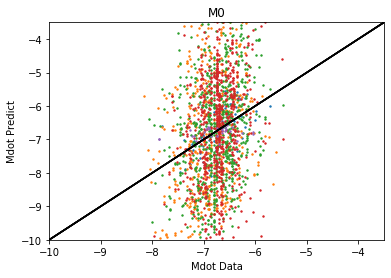

In [63]:
plot_predict_vs_real (M0_L_32_predicted_Mdot, np.transpose(M0_L_32)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_34_predicted_Mdot, np.transpose(M0_L_34)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_36_predicted_Mdot, np.transpose(M0_L_36)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_38_predicted_Mdot, np.transpose(M0_L_38)[0], label_title = 'M0')
plot_predict_vs_real (M0_L_40_predicted_Mdot, np.transpose(M0_L_40)[0], label_title = 'M0')

In [64]:
def mdot_bin (data_to_bin):
    bin_0 = []
    bin_1 = []
    bin_2 = []
    bin_3 = []
    bin_4 = []
    bin_5 = []
    bin_6 = []
    bin_7 = []
    for i in range (0,len(data_to_bin)):
        working_line = data_to_bin[i]
        if working_line[0] < -8: 
            bin_0.append(working_line.tolist())
        elif working_line[0] < -7.5: 
            bin_1.append(working_line.tolist())
        elif working_line[0] < -7: 
            bin_2.append(working_line.tolist())
        elif working_line[0] < -6.5:
            bin_3.append(working_line.tolist())
        elif working_line[0] < -6:
            bin_4.append(working_line.tolist())
        elif working_line[0] < -5.5:
            bin_5.append(working_line.tolist())
        elif working_line[0] < -5:
            bin_6.append(working_line.tolist())
        else:
            bin_7.append(working_line.tolist())
    #print(bin_0)
    return np.asarray(bin_0), np.asarray(bin_1), np.asarray(bin_2), np.asarray(bin_3), np.asarray(bin_4), np.asarray(bin_5), np.asarray(bin_6), np.asarray(bin_7)

In [65]:
M0_Mdot_8, M0_Mdot_75, M0_Mdot_7, M0_Mdot_65, M0_Mdot_6, M0_Mdot_55, M0_Mdot_5, M0_Mdot_plus = mdot_bin (M0StarData_to_be_fit)
M1_Mdot_8, M1_Mdot_75, M1_Mdot_7, M1_Mdot_65, M1_Mdot_6, M1_Mdot_55, M1_Mdot_5, M1_Mdot_plus = mdot_bin (M1StarData_to_be_fit)
C0_Mdot_8, C0_Mdot_75, C0_Mdot_7, C0_Mdot_65, C0_Mdot_6, C0_Mdot_55, C0_Mdot_5, C0_Mdot_plus = mdot_bin (C0StarData_to_be_fit)
C1_Mdot_8, C1_Mdot_75, C1_Mdot_7, C1_Mdot_65, C1_Mdot_6, C1_Mdot_55, C1_Mdot_5, C1_Mdot_plus = mdot_bin (C1StarData_to_be_fit)

In [66]:
# First, define function for ODR
def f10(B, x):
    '''Multi-Linear function y = B[0]*x + B[1]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]

def do_odr_fit_linear_PL (data_to_fit):
    linear = Model(f10)
    transposed_data = np.transpose(data_to_fit)
    logMdotData = transposed_data[0]
    logPData = transposed_data[1]
    logLData = transposed_data[2]
    mydata = Data(logPData,logLData)
    myodr = ODR(mydata,linear,beta0=[1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [78]:
fed_periods = np.asarray([ 1, 2, 3 ])
def generate_PL_fit_line (P_data, betas):
    return betas[0]*P_data+ betas[1]

In [133]:
PL_M0_Betas = do_odr_fit_linear_PL(M0StarData_to_be_fit)
fit_L_M0 = generate_PL_fit_line(fed_periods, PL_M0_Betas)

Beta: [1.30479948 0.66383017]
Beta Std Error: [0.02093522 0.04601657]
Beta Covariance: [[ 0.09214841 -0.20223106]
 [-0.20223106  0.4452062 ]]
Residual Variance: 0.004756279206342577
Inverse Condition #: 0.01774930922756655
Reason(s) for Halting:
  Sum of squares convergence


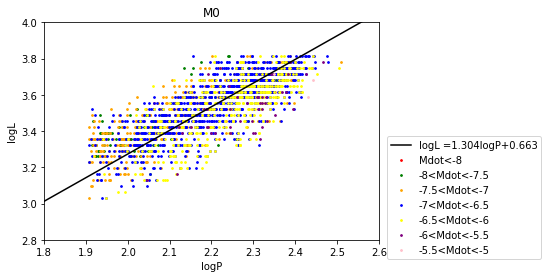

In [134]:
plot.scatter(np.transpose(M0_Mdot_8)[1],np.transpose(M0_Mdot_8)[2],s=3,label="Mdot<-8",color='r')
plot.scatter(np.transpose(M0_Mdot_75)[1],np.transpose(M0_Mdot_75)[2],s=3,label="-8<Mdot<-7.5",color='g')
plot.scatter(np.transpose(M0_Mdot_7)[1],np.transpose(M0_Mdot_7)[2],s=3,label="-7.5<Mdot<-7",color='orange')
plot.scatter(np.transpose(M0_Mdot_65)[1],np.transpose(M0_Mdot_65)[2],s=3,label="-7<Mdot<-6.5",color='b')
plot.scatter(np.transpose(M0_Mdot_6)[1],np.transpose(M0_Mdot_6)[2],s=3,label="-6.5<Mdot<-6",color='yellow')
plot.scatter(np.transpose(M0_Mdot_55)[1],np.transpose(M0_Mdot_55)[2],s=3,label="-6<Mdot<-5.5",color='purple')
plot.scatter(np.transpose(M0_Mdot_5)[1],np.transpose(M0_Mdot_5)[2],s=3,label="-5.5<Mdot<-5",color='pink')
fit_string = 'logL ='+str(PL_M0_Betas[0])[0:5]+'logP+'+str(PL_M0_Betas[1])[0:5]
plot.plot(fed_periods, fit_L_M0,color='k',label=fit_string)
#plot.scatter(np.transpose(M0_Mdot_plus)[1],np.transpose(M0_Mdot_plus)[2],s=3,label="Mdot>-5")
plot.xlim(1.8,2.6)
plot.ylim(2.8,4)
plot.xlabel('logP')
plot.ylabel('logL')
plot.title('M0')
plot.legend(bbox_to_anchor=(1.5, 0.5))

In [135]:
PL_M1_Betas = do_odr_fit_linear_PL(M1StarData_to_be_fit)
fit_L_M1 = generate_PL_fit_line(fed_periods, PL_M1_Betas)

Beta: [1.52478029 0.61980376]
Beta Std Error: [0.01287308 0.02508379]
Beta Covariance: [[ 0.07150652 -0.13893859]
 [-0.13893859  0.27149836]]
Residual Variance: 0.0023174965107243214
Inverse Condition #: 0.026185739232887847
Reason(s) for Halting:
  Sum of squares convergence


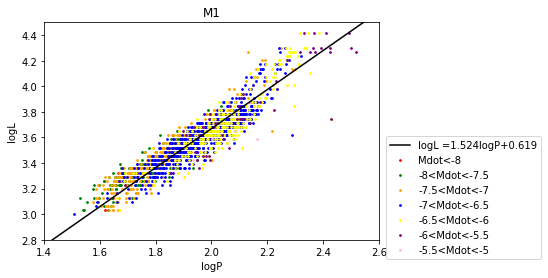

In [136]:
plot.scatter(np.transpose(M1_Mdot_8)[1],np.transpose(M1_Mdot_8)[2],s=3,label="Mdot<-8",color='r')
plot.scatter(np.transpose(M1_Mdot_75)[1],np.transpose(M1_Mdot_75)[2],s=3,label="-8<Mdot<-7.5",color='g')
plot.scatter(np.transpose(M1_Mdot_7)[1],np.transpose(M1_Mdot_7)[2],s=3,label="-7.5<Mdot<-7",color='orange')
plot.scatter(np.transpose(M1_Mdot_65)[1],np.transpose(M1_Mdot_65)[2],s=3,label="-7<Mdot<-6.5",color='b')
plot.scatter(np.transpose(M1_Mdot_6)[1],np.transpose(M1_Mdot_6)[2],s=3,label="-6.5<Mdot<-6",color='yellow')
plot.scatter(np.transpose(M1_Mdot_55)[1],np.transpose(M1_Mdot_55)[2],s=3,label="-6<Mdot<-5.5",color='purple')
plot.scatter(np.transpose(M1_Mdot_5)[1],np.transpose(M1_Mdot_5)[2],s=3,label="-5.5<Mdot<-5",color='pink')
fit_string = 'logL ='+str(PL_M1_Betas[0])[0:5]+'logP+'+str(PL_M1_Betas[1])[0:5]
plot.plot(fed_periods, fit_L_M1,color='k',label=fit_string)
#plot.scatter(np.transpose(M0_Mdot_plus)[1],np.transpose(M0_Mdot_plus)[2],s=3,label="Mdot>-5")
plot.xlim(1.4,2.6)
plot.ylim(2.8,4.5)
plot.xlabel('logP')
plot.ylabel('logL')
plot.title('M1')
plot.legend()
plot.legend(bbox_to_anchor=(1.5, 0.5))

In [137]:
PL_C0_Betas = do_odr_fit_linear_PL(C0StarData_to_be_fit)
fit_L_C0 = generate_PL_fit_line(fed_periods, PL_C0_Betas)

Beta: [ 1.98633563 -1.20384694]
Beta Std Error: [0.04360184 0.10998337]
Beta Covariance: [[ 0.39045823 -0.98441868]
 [-0.98441868  2.48438491]]
Residual Variance: 0.004868948129590217
Inverse Condition #: 0.009050970220537238
Reason(s) for Halting:
  Sum of squares convergence


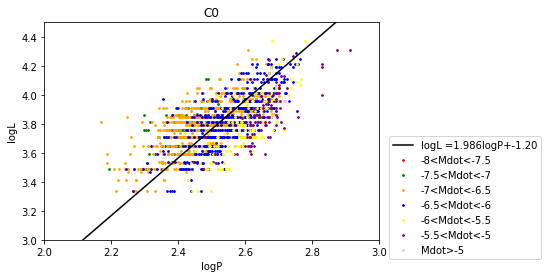

In [138]:
#plot.scatter(np.transpose(C0_Mdot_8)[1],np.transpose(C0_Mdot_8)[2],s=3,label="Mdot<-8")
plot.scatter(np.transpose(C0_Mdot_75)[1],np.transpose(C0_Mdot_75)[2],s=3,label="-8<Mdot<-7.5",color='r')
plot.scatter(np.transpose(C0_Mdot_7)[1],np.transpose(C0_Mdot_7)[2],s=3,label="-7.5<Mdot<-7",color='g')
plot.scatter(np.transpose(C0_Mdot_65)[1],np.transpose(C0_Mdot_65)[2],s=3,label="-7<Mdot<-6.5",color='orange')
plot.scatter(np.transpose(C0_Mdot_6)[1],np.transpose(C0_Mdot_6)[2],s=3,label="-6.5<Mdot<-6",color='b')
plot.scatter(np.transpose(C0_Mdot_55)[1],np.transpose(C0_Mdot_55)[2],s=3,label="-6<Mdot<-5.5",color='yellow')
plot.scatter(np.transpose(C0_Mdot_5)[1],np.transpose(C0_Mdot_5)[2],s=3,label="-5.5<Mdot<-5",color='purple')
plot.scatter(np.transpose(C0_Mdot_plus)[1],np.transpose(C0_Mdot_plus)[2],s=3,label="Mdot>-5",color='pink')
fit_string = 'logL ='+str(PL_C0_Betas[0])[0:5]+'logP+'+str(PL_C0_Betas[1])[0:5]
plot.plot(fed_periods, fit_L_C0,color='k',label=fit_string)
plot.xlim(2,3)
plot.ylim(3,4.5)
plot.xlabel('logP')
plot.ylabel('logL')
plot.title('C0')
plot.legend()
plot.legend(bbox_to_anchor=(1.5, 0.5))

In [139]:
PL_C1_Betas = do_odr_fit_linear_PL(C1StarData_to_be_fit)
fit_L_C1 = generate_PL_fit_line(fed_periods, PL_C1_Betas)

Beta: [ 1.7550389  -0.04526065]
Beta Std Error: [0.05606648 0.12508996]
Beta Covariance: [[ 0.8298591  -1.85032795]
 [-1.85032795  4.13088069]]
Residual Variance: 0.0037879328620439054
Inverse Condition #: 0.011128284359428352
Reason(s) for Halting:
  Sum of squares convergence


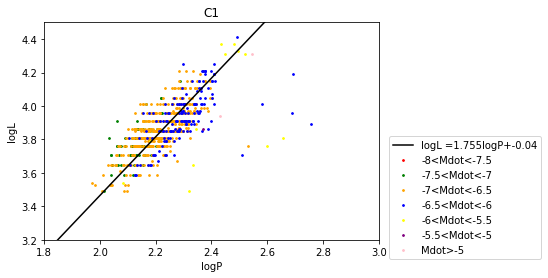

In [140]:
#plot.scatter(np.transpose(C1_Mdot_8)[1],np.transpose(C1_Mdot_8)[2],s=3,label="Mdot<-8")
plot.scatter(np.transpose(C1_Mdot_75)[1],np.transpose(C1_Mdot_75)[2],s=3,label="-8<Mdot<-7.5",color='r')
plot.scatter(np.transpose(C1_Mdot_7)[1],np.transpose(C1_Mdot_7)[2],s=3,label="-7.5<Mdot<-7",color='g')
plot.scatter(np.transpose(C1_Mdot_65)[1],np.transpose(C1_Mdot_65)[2],s=3,label="-7<Mdot<-6.5",color='orange')
plot.scatter(np.transpose(C1_Mdot_6)[1],np.transpose(C1_Mdot_6)[2],s=3,label="-6.5<Mdot<-6",color='b')
plot.scatter(np.transpose(C1_Mdot_55)[1],np.transpose(C1_Mdot_55)[2],s=3,label="-6<Mdot<-5.5",color='yellow')
plot.scatter(np.transpose(C1_Mdot_5)[1],np.transpose(C1_Mdot_5)[2],s=3,label="-5.5<Mdot<-5",color='purple')
plot.scatter(np.transpose(C1_Mdot_plus)[1],np.transpose(C1_Mdot_plus)[2],s=3,label="Mdot>-5",color='pink')
fit_string = 'logL ='+str(PL_C1_Betas[0])[0:5]+'logP+'+str(PL_C1_Betas[1])[0:5]
plot.plot(fed_periods, fit_L_C1,color='k',label=fit_string)
plot.xlim(1.8,3)
plot.ylim(3.2,4.5)
plot.xlabel('logP')
plot.ylabel('logL')
plot.title('C1')
plot.legend()
plot.legend(bbox_to_anchor=(1.5, 0.5))